# Mini-Project 2: Solar Micro-Grid Dispatch Planner
**Scenario.** A rural health centre in Kasese draws energy from solar panels (x) and batteries (y) so that
`3x + 2y = D1` (daytime load) and `4x + y = D2` (critical-equipment load), in kWh. Demand data are **synthetic** (seeded generator).

In [1]:
import sys; sys.path.insert(0, "..")
import timeit
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy import linalg
from src.microgrid import *

pd.set_option("display.float_format", "{:,.2f}".format)
grid = MicroGrid()
print(grid)

MicroGrid(A=[[3.0, 2.0], [4.0, 1.0]])


## Task 1: is the system well-posed?
* **Determinant** = 3*1 - 2*4 = **-5**. It is non-zero, so the two equations are independent and there is exactly one (x, y) for any demand pair. (A zero determinant would mean the equations are parallel: no solution or infinitely many.)
* **Condition number** (2-norm) measures how much relative input error can be amplified in the answer: `||dx||/||x|| <= cond(A) * ||dD||/||D||`. A value near 1 is ideal; values near 1/machine-epsilon (about 1e16) mean the matrix is numerically singular.

In [2]:
info = grid.check_well_posed()
print(info)
print("Example: D1=12, D2=11 ->", grid.solve_day(12, 11), "(true answer x=2, y=3)")

{'determinant': -4.999999999999999, 'condition_number': 5.82842712474619}
Example: D1=12, D2=11 -> [2. 3.] (true answer x=2, y=3)


With cond ≈ 5.8, this system is **well-conditioned**: a 1 % error in the demand figures can change the dispatch by at most about 5.8 %. The sensitivity analysis below checks this.

## Task 2: input modes
**(a) Interactive.** `prompt_demand` rejects empty, non-numeric, negative and non-finite input and re-prompts (run `python -m src.microgrid_cli` for the real `input()` version). Here the keyboard is simulated so the notebook runs unattended.

In [3]:
typed = iter(["", "abc", "-4", "nan", "72.5"])
value = prompt_demand("D1 (kWh): ", input_fn=lambda p: next(typed))
print("accepted:", value)

Invalid input: value is empty. Please try again.
Invalid input: 'abc' is not a number. Please try again.
Invalid input: value must not be negative. Please try again.
Invalid input: value must be finite. Please try again.
accepted: 72.5


**(b) CSV.** 30 days of demand, generated with `np.random.default_rng(2026)`: a weekly pattern (busy Mon-Fri, quiet weekend) plus noise.

In [4]:
csv_path = generate_demand_csv("../data/demand_30days.csv", n_days=30, seed=2026)
raw_df = pd.read_csv(csv_path)
display(raw_df.head(8))
D = load_demand_csv(csv_path)   # shape (2, 30)
print("D shape:", D.shape)

,day,weekday,d1_kwh,d2_kwh
0,1,Mon,76.19,80.78
1,2,Tue,74.44,100.42
2,3,Wed,84.73,78.54
3,4,Thu,78.50,84.47
4,5,Fri,74.78,70.56
5,6,Sat,58.42,65.94
6,7,Sun,47.82,46.79
7,8,Mon,80.77,68.37


D shape: (2, 30)


## Task 3: loop vs one vectorised call

In [5]:
sol_loop = grid.solve_loop(D)
sol_vec = grid.solve_vectorised(D)
print("same answer:", np.allclose(sol_loop, sol_vec))

n = 300
t_loop = timeit.timeit(lambda: grid.solve_loop(D), number=n) / n
t_bare = timeit.timeit(lambda: [linalg.solve(grid.A, D[:, j]) for j in range(30)], number=n) / n
t_vec  = timeit.timeit(lambda: linalg.solve(grid.A, D), number=n) / n
timing = pd.DataFrame({"time per 30 days (microseconds)": [t_loop*1e6, t_bare*1e6, t_vec*1e6]},
                      index=["loop via solve_day (with checks)", "bare loop of linalg.solve", "single vectorised call"])
timing["speed-up vs vectorised"] = timing.iloc[:, 0] / (t_vec * 1e6)
display(timing)

same answer: True


,time per 30 days (microseconds),speed-up vs vectorised
loop via solve_day (with checks),"4,994.63",15.21
bare loop of linalg.solve,"2,036.14",6.20
single vectorised call,328.28,1.00


The vectorised call factorises A (LU) **once** and back-substitutes 30 right-hand sides, while the loop re-factorises 30 times and pays Python call overhead each time. My `solve_day` is slower still because it re-checks determinant and condition number on every call; that is useful for a single interactive solve, wasteful in a batch. (Exact timings vary by machine.)

## Task 4: infeasible days
A solution with x < 0 or y < 0 asks the plant to push energy *into* a source, which is physically impossible. Handling strategy: **non-negative least squares** (`scipy.optimize.nnls`), which finds the non-negative dispatch whose loads are closest to the demand, and a report of the kWh left unmet. Compared with clipping negatives to 0, NNLS re-optimises the other source rather than just truncating one.

In [6]:
rep = grid.handle_infeasible(D)
print(f"{rep.n_infeasible} of 30 days infeasible: days {[j+1 for j in rep.infeasible_days]}")
flag = pd.DataFrame({
    "day": [j+1 for j in rep.infeasible_days],
    "D1": D[0, rep.infeasible_days], "D2": D[1, rep.infeasible_days],
    "exact x": rep.raw[0, rep.infeasible_days], "exact y": rep.raw[1, rep.infeasible_days],
    "NNLS x": rep.handled[0, rep.infeasible_days], "NNLS y": rep.handled[1, rep.infeasible_days],
    "unmet D1": rep.unmet[0, rep.infeasible_days], "unmet D2": rep.unmet[1, rep.infeasible_days]}).set_index("day")
display(flag)
print("Total unmet load (kWh): D1 %.1f (%.2f%% of demand), D2 %.1f (%.2f%%)" % (
    rep.unmet[0].sum(), 100*rep.unmet[0].sum()/D[0].sum(), rep.unmet[1].sum(), 100*rep.unmet[1].sum()/D[1].sum()))
print("All handled values non-negative:", bool((rep.handled >= 0).all()))

6 of 30 days infeasible: days [2, 13, 14, 16, 22, 25]


,D1,D2,exact x,exact y,NNLS x,NNLS y,unmet D1,unmet D2
day,,,,,,,,
2,74.44,100.42,25.28,-0.70,25.00,0.00,0.56,0.42
13,58.16,84.68,22.24,-4.28,20.53,0.00,3.42,2.57
14,45.95,61.43,15.38,-0.10,15.34,0.00,0.08,0.06
16,78.11,104.49,26.17,-0.21,26.09,0.00,0.16,0.12
22,76.04,103.49,26.19,-1.26,25.68,0.00,1.01,0.76
25,92.29,164.98,47.53,-25.16,37.47,0.00,20.12,15.09


Total unmet load (kWh): D1 25.4 (1.16% of demand), D2 19.0 (0.78%)
All handled values non-negative: True


## Task 5: volatility of solar vs battery (using the handled, feasible dispatch)

In [7]:
x, y = rep.handled
summary = pd.DataFrame({"solar x": describe(x), "battery y": describe(y)}).T
summary.columns = ["mean (kWh)", "variance (kWh^2)", "std (kWh)", "CV (std/mean)"]
display(summary)

,mean (kWh),variance (kWh^2),std (kWh),CV (std/mean)
solar x,17.37,48.46,6.96,0.40
battery y,10.86,84.70,9.20,0.85


The battery is more volatile on both measures: a larger standard deviation **and** a larger coefficient of variation (CV), which matters because the means differ. CV is the fairer comparison.

## Task 6: cost model (solar UGX 150/kWh, battery UGX 450/kWh)

In [8]:
cost = CostModel(solar_price=150, battery_price=450)
daily_cost = cost.daily_cost(rep.handled)
print(f"Daily cost: min UGX {daily_cost.min():,.0f}, mean UGX {daily_cost.mean():,.0f}, max UGX {daily_cost.max():,.0f}")
print(f"Monthly (30-day) cost: UGX {cost.monthly_cost(rep.handled):,.0f}")
print(f"Battery share of cost: {100*450*y.sum()/daily_cost.sum():.1f}% (but only {100*y.sum()/(x.sum()+y.sum()):.1f}% of energy)")

Daily cost: min UGX 2,301, mean UGX 7,494, max UGX 15,557
Monthly (30-day) cost: UGX 224,812
Battery share of cost: 65.2% (but only 38.5% of energy)


## Task 7: daily usage (stacked) and cost (second axis)

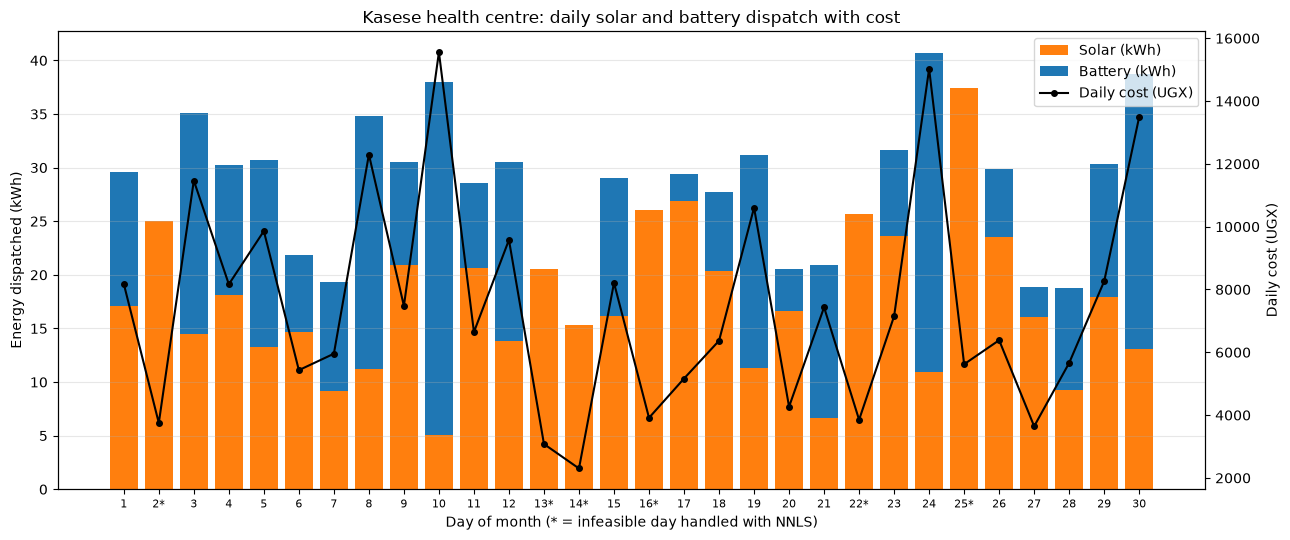

In [9]:
days = np.arange(1, 31)
fig, ax = plt.subplots(figsize=(13, 5.5))
ax.bar(days, x, color="tab:orange", label="Solar (kWh)")
ax.bar(days, y, bottom=x, color="tab:blue", label="Battery (kWh)")
ax.set_xlabel("Day of month (* = infeasible day handled with NNLS)")
ax.set_ylabel("Energy dispatched (kWh)")
ax.set_xticks(days)
ax.set_xticklabels([f"{d}*" if (d-1) in rep.infeasible_days else str(d) for d in days], fontsize=8)
ax2 = ax.twinx()
ax2.plot(days, daily_cost, "k-o", ms=4, label="Daily cost (UGX)")
ax2.set_ylabel("Daily cost (UGX)")
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="upper right")
ax.set_title("Kasese health centre: daily solar and battery dispatch with cost")
ax.grid(axis="y", alpha=0.3)
fig.tight_layout(); fig.savefig("../figures/p2_dispatch.png", dpi=150); plt.show()

## Extension A: hybrid grid with a diesel generator (3x3)
Third constraint I chose: `x + y + z = D3`, the total energy dispatched must equal the day's total requirement. Diesel also enters the first two equations (coefficients 1 and 2).

In [10]:
hyb = HybridMicroGrid()
print(hyb.A, "\ndet =", round(hyb.determinant(), 3), " cond =", round(hyb.condition_number(), 2))
true = np.array([10.0, 6.0, 4.0])
print("recover known dispatch:", hyb.solve_day(*(hyb.A @ true)))

# What if the new equation is linearly dependent? row3 = row1 + row2
dep = HybridMicroGrid([[3, 2, 1], [4, 1, 2], [7, 3, 3]])
print("\ndependent system: det =", dep.determinant(), " cond =", f"{dep.condition_number():.2e}")
try:
    dep.solve_day(10, 12, 22)
except SingularSystemError as e:
    print("blocked ->", e)

[[3. 2. 1.]
 [4. 1. 2.]
 [1. 1. 1.]] 
det = -4.0  cond = 10.06
recover known dispatch: [10.  6.  4.]

dependent system: det = 2.2204460492503135e-15  cond = 2.48e+16
blocked -> system is singular or ill-conditioned (det=2.22e-15, cond=2.48e+16)


If the third equation is a combination of the first two, it carries no new information: the determinant is 0, the condition number explodes (about 1e16), and the system has either **infinitely many solutions** (the demands are consistent, so diesel can be traded off against solar and battery) or **none** (they are inconsistent). `HybridMicroGrid` refuses to solve it rather than return rounding noise; the fix is to add a genuinely independent equation (e.g. a cost or capacity limit) or optimise with a cost objective.

## Extension B: sensitivity to +/-5 % demand error (Monte Carlo, 1,000 draws)

Base dispatch (x, y): [17.79  9.81]
Std of x, y over draws: [1.02 2.18]
Largest input change 4.9% -> largest output change 27.6%
Worst amplification 5.79  vs  cond(A) = 5.83


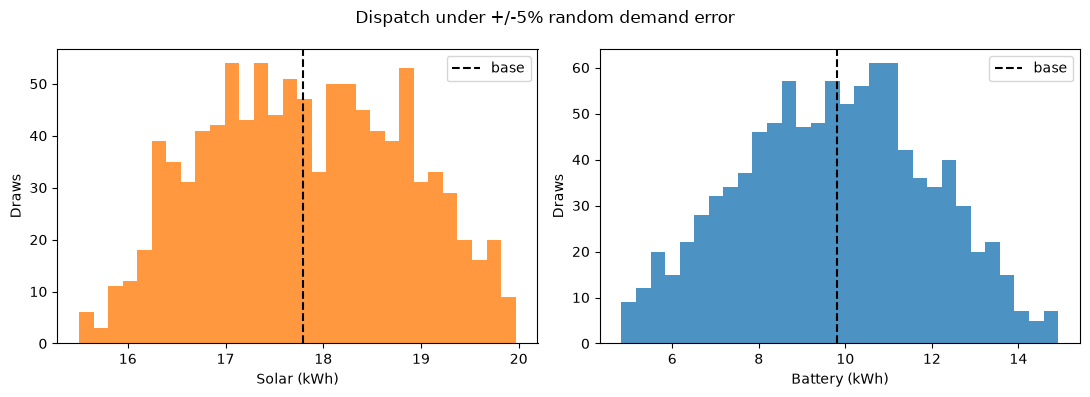

In [11]:
mean_demand = D.mean(axis=1)
mc = grid.monte_carlo_sensitivity(mean_demand, pct=0.05, n_draws=1000, seed=7)
amp = mc["rel_out"] / mc["rel_in"]
print("Base dispatch (x, y):", mc["base"].round(2))
print("Std of x, y over draws:", mc["solutions"].std(axis=1).round(2))
print(f"Largest input change {100*mc['rel_in'].max():.1f}% -> largest output change {100*mc['rel_out'].max():.1f}%")
print(f"Worst amplification {amp.max():.2f}  vs  cond(A) = {grid.condition_number():.2f}")
fig, axs = plt.subplots(1, 2, figsize=(11, 4))
for a, k, c in zip(axs, (0, 1), ("tab:orange", "tab:blue")):
    a.hist(mc["solutions"][k], bins=30, color=c, alpha=0.8)
    a.axvline(mc["base"][k], color="k", ls="--", label="base")
    a.set_xlabel(f"{grid.source_names[k].title()} (kWh)"); a.set_ylabel("Draws"); a.legend()
fig.suptitle("Dispatch under +/-5% random demand error"); fig.tight_layout()
fig.savefig("../figures/p2_sensitivity.png", dpi=150); plt.show()

## Findings & Limitations
**Findings.** The system is well-posed: det(A) = -5 and cond(A) ≈ 5.8, so each day has one unique solution and small input errors are not violently amplified. The Monte Carlo test confirms this: demand errors of up to 5 % moved the dispatch by up to about 28 % (relative to its size), with the worst amplification (≈ 5.8) matching the condition number, which is the theoretical upper bound. The battery is the more volatile source (CV ≈ 0.85 against ≈ 0.40 for solar) and the more sensitive one, because y = (4·D1 − 3·D2)/5 is a difference of two large terms. Six of 30 days (20 %) are infeasible because D2 is too large relative to D1, which forces a negative battery value. Handling them with NNLS leaves only about 1 % of total demand unmet, mostly on one day (day 25), whereas the exact solution would have been physically impossible. The monthly bill is about UGX 225,000, with the battery supplying about 39 % of the energy but about 65 % of the cost (UGX 450 vs 150 per kWh), so shifting load towards solar is the main saving lever. The vectorised solve is far faster than a loop.

**Limitations.** Demands are synthetic, and the 20 % infeasibility rate is a product of my generator's noise, not a real finding. The model has no battery state of charge, capacity limit or time-of-day dynamics, and the prices are illustrative. The diesel row (x + y + z = D3) is an arbitrary choice and its prices are assumed. NNLS minimises squared kWh error and does not prioritise the critical-equipment load, which a real planner should.